## Task 1: NLP Fundamentals, Pipeline & Data Exploration

### 1.1 What is NLP and why do we need it?

Natural Language Processing (NLP) is a part of Artificial Intelligence that helps computers understand and work with human language. People create a huge amount of text every day, such as messages, reviews, emails and social media posts. This text is unstructured, so computers need NLP techniques to process it. NLP is used in search engines, spam filtering, chatbots, machine translation and customer-review analysis. In India, chatbots can answer customer questions in English and Indian languages. Machine translation can help people translate information between Gujarati, Hindi and English. NLP also helps companies understand customer feedback and improve their services.



### 1.2 Common NLP tasks and approaches

| NLP task | Description | Example |
|---|---|---|
| Text classification | Assigns a category to text. | Spam or not spam |
| Sentiment analysis | Finds positive, negative or neutral feelings. | Positive product review |
| Named-entity recognition | Finds names, places and organisations. | Surat, India |
| POS tagging | Finds the grammar role of each word. | `flight` = noun |
| Machine translation | Changes text from one language to another. | Gujarati to English |
| Summarisation | Creates a short version of long text. | News summary |
| Question answering | Gives an answer to a question. | Chatbot answer |

| Approach | Meaning | Example |
|---|---|---|
| Heuristic | Uses manually written rules and word lists. | Positive/negative word counting |
| API-based | Uses a ready-made service or engine. | NLTK VADER |
| Machine-Learning-based | Learns patterns from labelled examples. | BoW, N-grams, TF-IDF, Word2Vec |

**Interpretation -** Different NLP tasks solve different language problems. This practical compares rule-based, ready-made and machine-learning approaches.

### 1.3 NLP pipeline

1. **Data collection (Task 1):** Load airline tweets from `Tweets.csv`.
2. **Text cleaning (Task 2):** Remove URLs, mentions, punctuation and extra spaces.
3. **Tokenisation (Task 2):** Split cleaned tweets into words.
4. **Stop-word handling (Task 2):** Remove common words but keep negation words.
5. **Feature extraction (Tasks 4–5):** Convert text into BoW, TF-IDF and Word2Vec vectors.
6. **Model training (Task 6):** Train text classifiers using training tweets.
7. **Evaluation (Tasks 3 and 6):** Compare accuracy, macro-F1 and confusion matrices.
8. **Deployment (Task 8):** The separate Streamlit app uses the saved model.

**Interpretation -** Each stage prepares the text for the next stage and helps build a reliable sentiment model.

### 1.4 Load and inspect the dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import time
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

df = pd.read_csv('Tweets.csv')
print('Dataset shape:', df.shape)
print(df[['text', 'airline_sentiment', 'airline']].head())
print('Null values:')
print(df[['text', 'airline_sentiment', 'airline']].isnull().sum())
print('Duplicate tweets:', df['text'].duplicated().sum())

df = df.drop_duplicates().dropna(subset=['text', 'airline_sentiment', 'airline']).copy()
df['text'] = df['text'].astype(str)
df['airline_sentiment'] = df['airline_sentiment'].astype(str)
print('Shape after removing duplicates and missing rows:', df.shape)

for i, tweet in enumerate(df['text'].head(5), 1):
    print(f'Raw tweet {i}: {tweet}')

Dataset shape: (14640, 15)
                                                text airline_sentiment  \
0                @VirginAmerica What @dhepburn said.           neutral   
1  @VirginAmerica plus you've added commercials t...          positive   
2  @VirginAmerica I didn't today... Must mean I n...           neutral   
3  @VirginAmerica it's really aggressive to blast...          negative   
4  @VirginAmerica and it's a really big bad thing...          negative   

          airline  
0  Virgin America  
1  Virgin America  
2  Virgin America  
3  Virgin America  
4  Virgin America  
Null values:
text                 0
airline_sentiment    0
airline              0
dtype: int64
Duplicate tweets: 213
Shape after removing duplicates and missing rows: (14604, 15)
Raw tweet 1: @VirginAmerica What @dhepburn said.
Raw tweet 2: @VirginAmerica plus you've added commercials to the experience... tacky.
Raw tweet 3: @VirginAmerica I didn't today... Must mean I need to take another trip!
Raw tweet

**Interpretation -** The dataset contains real airline tweets and their sentiment labels. Duplicate and incomplete rows are removed before analysis.

### 1.5 EDA plots

                   Count  Percentage
airline_sentiment                   
negative            9159       62.72
neutral             3091       21.17
positive            2354       16.12


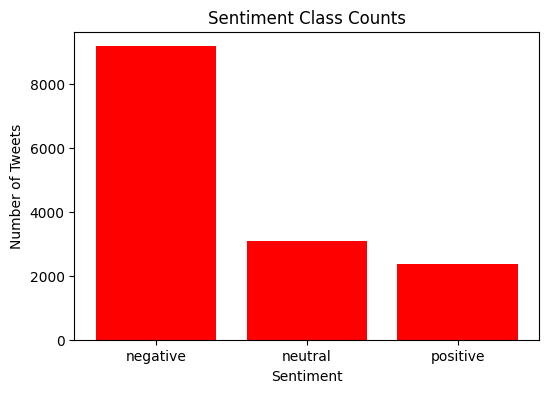

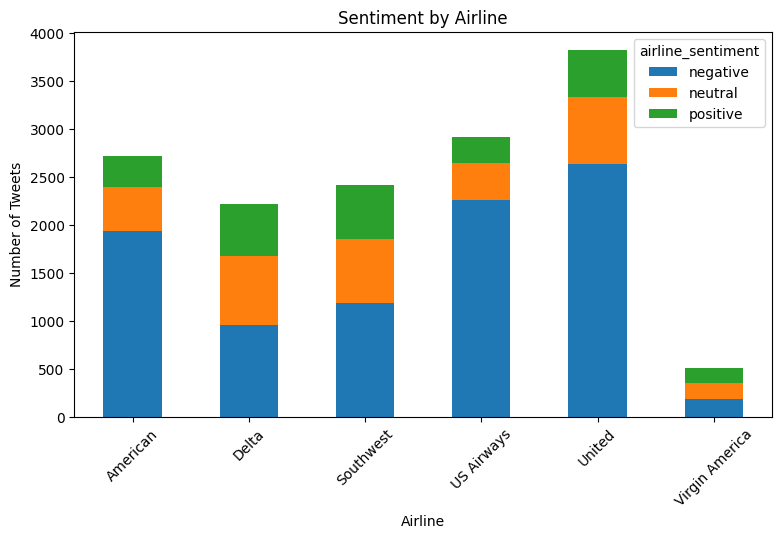

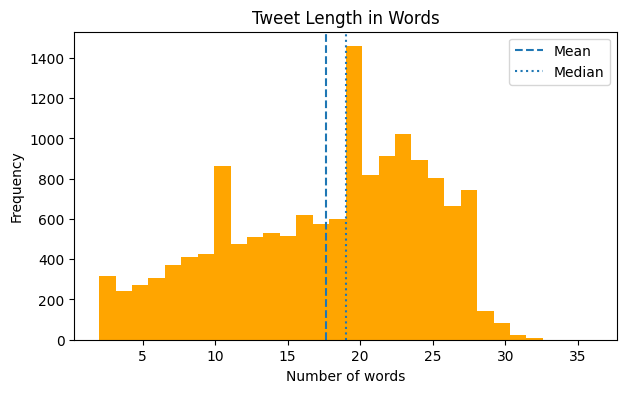

Mean tweet length: 17.66
Median tweet length: 19.0


In [3]:
# Sentiment counts and percentages
sent_count = df['airline_sentiment'].value_counts()
sent_percent = df['airline_sentiment'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': sent_count, 'Percentage': sent_percent.round(2)}))

plt.figure(figsize=(6, 4))
plt.bar(sent_count.index, sent_count.values, color='red')                                                             
plt.title('Sentiment Class Counts')
plt.xlabel('Sentiment')
plt.ylabel('Number of Tweets')
plt.show()

# Sentiment by airline
airline_sent = pd.crosstab(df['airline'], df['airline_sentiment'])
airline_sent.plot(kind='bar', stacked=True, figsize=(9, 5))
plt.title('Sentiment by Airline')
plt.xlabel('Airline')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=45)
plt.show()

# Tweet length
df['tweet_length'] = df['text'].apply(lambda x: len(x.split()))
mean_len = df['tweet_length'].mean()
median_len = df['tweet_length'].median()
plt.figure(figsize=(7, 4))
plt.hist(df['tweet_length'], bins=30, color='orange')
plt.axvline(mean_len, linestyle='--', label='Mean')
plt.axvline(median_len, linestyle=':', label='Median')
plt.title('Tweet Length in Words')
plt.xlabel('Number of words')
plt.ylabel('Frequency')
plt.legend()
plt.show()

print('Mean tweet length:', round(mean_len, 2))
print('Median tweet length:', round(median_len, 2))

**Interpretation -** The sentiment chart shows the class balance. If negative tweets are much more common, accuracy alone may hide poor performance on neutral and positive tweets. Macro-F1 gives equal importance to each class.

### 1.6 Challenges in NLP — real tweet examples

The examples below are selected from the dataset using simple keyword searches. If a category has no matching example, the table may contain fewer than five rows.

In [4]:
challenge_words = {
    'Negation': [' not ', ' never ', ' no '],
    'Sarcasm or irony': [' yeah right', ' thanks for nothing', ' great job'],
    'Slang or misspelling': [' lol', ' omg', ' u ', ' ur '],
    'Emoji or special symbols': ['!', '#', '$', ':)', '😡', '😂'],
    'Hard to label': [' but ', ' although ', ' however ']
}

challenge_rows = []
for label, words in challenge_words.items():
    mask = df['text'].str.lower().apply(lambda x: any(w in x for w in words))
    found = df.loc[mask, 'text'].head(1)
    if len(found) > 0:
        challenge_rows.append({'Challenge': label, 'Tweet': found.iloc[0],
                               'Why it is hard': 'The text may need context, tone or special-word understanding.'})

challenge_table = pd.DataFrame(challenge_rows)
display(challenge_table)

,Challenge,Tweet,Why it is hard
0,Negation,@VirginAmerica status match program. I applie...,"The text may need context, tone or special-wor..."
1,Sarcasm or irony,"@VirginAmerica a lot of ""apologies"" being thro...","The text may need context, tone or special-wor..."
2,Slang or misspelling,@VirginAmerica @virginmedia I'm flying your #f...,"The text may need context, tone or special-wor..."
3,Emoji or special symbols,@VirginAmerica I didn't today... Must mean I n...,"The text may need context, tone or special-wor..."
4,Hard to label,@VirginAmerica So excited for my first cross c...,"The text may need context, tone or special-wor..."


**Interpretation -** Negation, sarcasm, informal spelling and symbols can change the meaning of a tweet. A computer may not understand these clues from individual words alone.

## Task 2: Text Cleaning with RegEx & Tokenisation

### 2.1 Cleaning rules

| Rule | Why it is used | Possible information loss |
|---|---|---|
| Lowercase | Treats uppercase and lowercase words equally. | Emphasis from capital letters is lost. |
| Remove URLs | Removes web addresses. | Link information is lost. |
| Remove @mentions | Removes user names. | The mentioned account is lost. |
| Keep hashtag word | Removes `#` but keeps the word. | Hashtag formatting is lost. |
| Remove numbers | Removes digits. | Flight numbers and dates are lost. |
| Remove punctuation | Keeps simple word tokens. | `!!!` may show strong emotion. |
| Collapse spaces | Removes extra spaces. | No important meaning is usually lost. |
| Remove stop-words | Removes common words. | Negation must be protected. |

**Interpretation -** Cleaning makes tweets easier to process, but some rules can remove useful information such as emphasis and emojis.

### 2.2 RegEx practice cells

In [5]:
examples = [
    'Visit https://airline.com now',
    'Thanks @airline for help',
    'I love #CustomerService',
    'Flight 123 is late',
    'Wow!!! This is bad.',
    'too     much     delay'
]

print('URL:', re.sub(r'https?://\\S+', '', examples[0]))
print('Mention:', re.sub(r'@\\w+', '', examples[1]))
print('Hashtag:', re.sub(r'#(\\w+)', r'\\1', examples[2]))
print('Numbers:', re.sub(r'\\d+', '', examples[3]))
print('Punctuation:', re.sub(r'[^a-zA-Z\\s]', '', examples[4]))
print('Extra spaces:', re.sub(r'\\s+', ' ', examples[5]).strip())

URL: Visit https://airline.com now
Mention: Thanks @airline for help
Hashtag: I love #CustomerService
Numbers: Flight 123 is late
Punctuation: WowThisisbad
Extra spaces: too     much     delay


| Pattern | Meaning | Example match |
|---|---|---|
| `https?://\\S+` | `http` or `https`, followed by non-space characters | `https://site.com` |
| `@\\w+` | `@` followed by word characters | `@airline` |
| `#(\\w+)` | Captures the word after `#` | `#help` → `help` |
| `\\d+` | One or more digits | `123` |
| `[^a-zA-Z\\s]` | Characters other than letters and spaces | `!`, `#`, `5` |
| `\\s+` | One or more whitespace characters | Multiple spaces |

**Interpretation -** RegEx patterns find text patterns and remove unwanted parts of tweets.

### 2.3 clean_text() function

In [6]:
def clean_text(s):
    s = str(s).lower()
    s = re.sub(r'https?://\\S+', ' ', s)
    s = re.sub(r'www\\.\\S+', ' ', s)
    s = re.sub(r'@\\w+', ' ', s)
    s = re.sub(r'#(\\w+)', r'\\1', s)
    s = re.sub(r'\\d+', ' ', s)
    s = re.sub(r'[^a-z\\s]', ' ', s)
    s = re.sub(r'\\s+', ' ', s).strip()
    return s

df['clean_text'] = df['text'].apply(clean_text)
display(df[['text', 'clean_text']].head(5))

empty_count = (df['clean_text'].str.strip() == '').sum()
print('Empty tweets after cleaning:', empty_count)
df = df[df['clean_text'].str.strip() != ''].copy()
print('Shape after removing empty cleaned tweets:', df.shape)

,text,clean_text
0,@VirginAmerica What @dhepburn said.,virginamerica what dhepburn said
1,@VirginAmerica plus you've added commercials t...,virginamerica plus you ve added commercials to...
2,@VirginAmerica I didn't today... Must mean I n...,virginamerica i didn t today must mean i ne...
3,@VirginAmerica it's really aggressive to blast...,virginamerica it s really aggressive to blast ...
4,@VirginAmerica and it's a really big bad thing...,virginamerica and it s a really big bad thing ...


Empty tweets after cleaning: 0
Shape after removing empty cleaned tweets: (14604, 17)


**Interpretation -** The function applies cleaning rules in order. Tweets that become empty are counted and removed so they do not create empty model inputs.

### 2.4 Tokenisation and stop-words

In [7]:
import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words('english'))
for w in ['no', 'not', 'nor', 'never']:
    stop_words.discard(w)

def get_tokens(s):
    return [w for w in word_tokenize(s) if w.isalpha() and w not in stop_words]

example = 'not happy with the delay'
print('Before:', word_tokenize(example))
print('After:', [w for w in word_tokenize(example) if w not in stop_words])

df['tokens'] = df['clean_text'].apply(get_tokens)
print('Token example:', df['tokens'].iloc[0])

Before: ['not', 'happy', 'with', 'the', 'delay']
After: ['not', 'happy', 'delay']
Token example: ['virginamerica', 'dhepburn', 'said']


**Interpretation -** Negation words such as `not` are kept. Removing them can change “not happy” into “happy” and reverse the sentence meaning.

### 2.5 Vocabulary statistics

Vocabulary before stop-word removal: 13661
Vocabulary after stop-word removal: 13515
\nTop 20 words for negative
[('flight', 2953), ('united', 2900), ('usairways', 2375), ('americanair', 2091), ('not', 1401), ('no', 1322), ('southwestair', 1214), ('jetblue', 1052), ('get', 990), ('cancelled', 921), ('service', 748), ('hours', 656), ('help', 618), ('hold', 611), ('customer', 611), ('time', 597), ('plane', 530), ('delayed', 505), ('amp', 503), ('us', 502)]
\nTop 20 words for neutral
[('jetblue', 748), ('united', 739), ('southwestair', 671), ('flight', 614), ('co', 525), ('http', 500), ('americanair', 491), ('usairways', 402), ('get', 238), ('please', 182), ('virginamerica', 177), ('help', 171), ('flights', 169), ('need', 163), ('thanks', 157), ('not', 156), ('dm', 133), ('would', 123), ('no', 119), ('us', 112)]
\nTop 20 words for positive
[('thanks', 606), ('jetblue', 595), ('southwestair', 576), ('united', 528), ('thank', 454), ('flight', 382), ('americanair', 346), ('usairways', 276), 

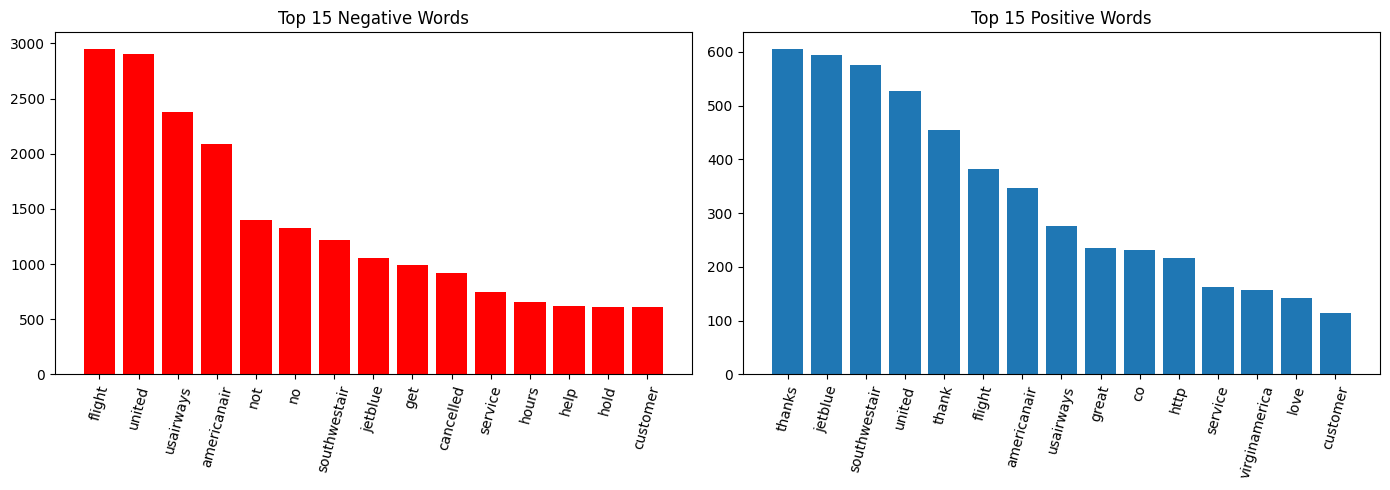

In [8]:
from collections import Counter

all_words = [w for row in df['clean_text'].str.split() for w in row]
clean_words = [w for row in df['tokens'] for w in row]
print('Vocabulary before stop-word removal:', len(set(all_words)))
print('Vocabulary after stop-word removal:', len(set(clean_words)))

for label in ['negative', 'neutral', 'positive']:
    words = [w for row in df.loc[df['airline_sentiment'] == label, 'tokens'] for w in row]
    print('\\nTop 20 words for', label)
    print(Counter(words).most_common(20))

freq = Counter(clean_words)
print('Words appearing only once:', sum(1 for w, c in freq.items() if c == 1))

neg_words = [w for row in df.loc[df['airline_sentiment'] == 'negative', 'tokens'] for w in row]
pos_words = [w for row in df.loc[df['airline_sentiment'] == 'positive', 'tokens'] for w in row]
neg_top = Counter(neg_words).most_common(15)
pos_top = Counter(pos_words).most_common(15)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].bar([x[0] for x in neg_top], [x[1] for x in neg_top] ,color='red')
ax[0].set_title('Top 15 Negative Words')
ax[0].tick_params(axis='x', rotation=75)
ax[1].bar([x[0] for x in pos_top], [x[1] for x in pos_top])
ax[1].set_title('Top 15 Positive Words')
ax[1].tick_params(axis='x', rotation=75)
plt.tight_layout()
plt.show()

**Interpretation -** Frequent words show common topics in each sentiment class. Rare words may be noise, so `min_df` can remove very rare terms and `max_features` can limit vocabulary size.

## Task 3: Different NLP Approaches — Heuristic & API-based


### 3.1 Approaches overview

- **Heuristic:** Uses manually selected positive and negative words. It is simple and does not need training, but it may miss context and sarcasm.
- **API-based:** Uses a ready-made sentiment engine such as VADER. It is quick to use, but a general engine may not understand every airline-specific expression.
- **Machine-learning-based:** Learns patterns from labelled tweets. It can fit the airline domain, but it needs labelled data and training.

A company may choose a heuristic method for a small, low-budget task; an API for a quick solution; and a trained ML model when enough data is available and domain accuracy and privacy can be managed. Cloud services such as Google Cloud Natural Language, AWS Comprehend and Azure Text Analytics accept text and return sentiment results. They need an account, API key and may involve billing.

**Interpretation -** Each approach has different costs, data needs and accuracy. The test results will show how they perform on this dataset.

### 3.2 Heuristic approach

In [9]:
positive_words = set('great good excellent amazing awesome love thanks thank helpful friendly wonderful best nice happy appreciate quick smooth comfortable helpful crew service clean easy'.split())
negative_words = set('bad worst terrible awful hate delay delayed late cancel cancelled rude lost broken poor slow problem issue angry disappointed horrible wait mistake'.split())
negations = {'not', 'no', 'never'}

def heuristic_sentiment(text):
    words = str(text).lower().split()
    pos = 0
    neg = 0
    for i, word in enumerate(words):
        if word in positive_words:
            if i > 0 and words[i-1] in negations:
                neg += 1
            elif i > 1 and words[i-2] in negations:
                neg += 1
            else:
                pos += 1
        if word in negative_words:
            if i > 0 and words[i-1] in negations:
                pos += 1
            elif i > 1 and words[i-2] in negations:
                pos += 1
            else:
                neg += 1
    if pos > neg:
        label = 'positive'
    elif neg > pos:
        label = 'negative'
    else:
        label = 'neutral'
    return label, pos, neg

for t in df['clean_text'].head(5):
    print(t, '->', heuristic_sentiment(t))

virginamerica what  dhepburn said -> ('neutral', 0, 0)
virginamerica plus you ve added commercials to the experience    tacky -> ('neutral', 0, 0)
virginamerica i didn t today    must mean i need to take another trip -> ('neutral', 0, 0)
virginamerica it s really aggressive to blast obnoxious  entertainment  in your guests  faces  amp  they have little recourse -> ('neutral', 0, 0)
virginamerica and it s a really big bad thing about it -> ('negative', 0, 1)


**Interpretation -** The heuristic method counts positive and negative words. A nearby negation word changes the word's polarity. This small word list is only a simple baseline.

### 3.3 API-based approach — VADER

In [10]:
nltk.download('vader_lexicon', quiet=True)
from nltk.sentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()

def vader_sentiment(text):
    score = vader.polarity_scores(str(text))['compound']
    if score >= 0.05:
        label = 'positive'
    elif score <= -0.05:
        label = 'negative'
    else:
        label = 'neutral'
    return label

df['heuristic_pred'] = df['clean_text'].apply(lambda x: heuristic_sentiment(x)[0])
df['vader_pred'] = df['text'].apply(vader_sentiment)
print(df[['text', 'heuristic_pred', 'vader_pred']].head())

                                                text heuristic_pred vader_pred
0                @VirginAmerica What @dhepburn said.        neutral    neutral
1  @VirginAmerica plus you've added commercials t...        neutral    neutral
2  @VirginAmerica I didn't today... Must mean I n...        neutral    neutral
3  @VirginAmerica it's really aggressive to blast...        neutral   negative
4  @VirginAmerica and it's a really big bad thing...       negative   negative


**Interpretation -** VADER returns a compound sentiment score. The score thresholds convert it into positive, negative or neutral. No model training is needed for VADER.

### 3.4 Evaluate both approaches on the same test set

Heuristic
Accuracy: 0.4611
Macro-F1: 0.4817
              precision    recall  f1-score   support

    negative       0.92      0.29      0.44      1832
     neutral       0.29      0.81      0.43       618
    positive       0.50      0.68      0.58       471

    accuracy                           0.46      2921
   macro avg       0.57      0.59      0.48      2921
weighted avg       0.72      0.46      0.46      2921



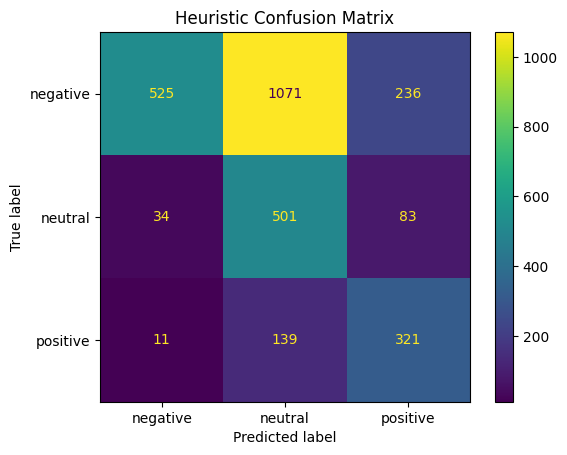

VADER
Accuracy: 0.5375
Macro-F1: 0.5078
              precision    recall  f1-score   support

    negative       0.90      0.48      0.63      1832
     neutral       0.39      0.44      0.41       618
    positive       0.33      0.88      0.48       471

    accuracy                           0.54      2921
   macro avg       0.54      0.60      0.51      2921
weighted avg       0.70      0.54      0.56      2921



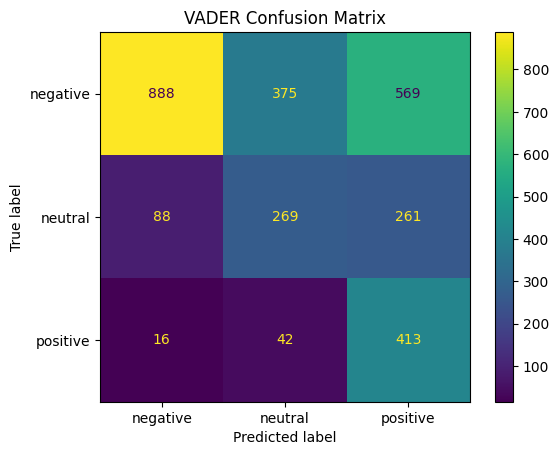

,Approach,Accuracy,Macro-F1
0,Heuristic,0.461143,0.481740
1,VADER,0.537487,0.507795


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, precision_score, recall_score
from sklearn.metrics import ConfusionMatrixDisplay

X = df['clean_text']
y = df['airline_sentiment']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
test_index = X_test.index
y_test = y.loc[test_index]
h_pred = df.loc[test_index, 'heuristic_pred']
v_pred = df.loc[test_index, 'vader_pred']

def show_scores(name, true, pred):
    print(name)
    print('Accuracy:', round(accuracy_score(true, pred), 4))
    print('Macro-F1:', round(f1_score(true, pred, average='macro'), 4))
    print(classification_report(true, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(true, pred)
    plt.title(name + ' Confusion Matrix')
    plt.show()

show_scores('Heuristic', y_test, h_pred)
show_scores('VADER', y_test, v_pred)

approach_scores = pd.DataFrame([
    {'Approach': 'Heuristic', 'Accuracy': accuracy_score(y_test, h_pred),
     'Macro-F1': f1_score(y_test, h_pred, average='macro')},
    {'Approach': 'VADER', 'Accuracy': accuracy_score(y_test, v_pred),
     'Macro-F1': f1_score(y_test, v_pred, average='macro')}
])
display(approach_scores)

**Interpretation -** Accuracy measures total correct predictions. Macro-F1 gives equal weight to each sentiment class, which is useful for this imbalanced dataset. Use the printed values as the measured results.

### 3.5 Where do rules and ready-made tools fail?

In [12]:
for name, pred in [('Heuristic', h_pred), ('VADER', v_pred)]:
    wrong = df.loc[test_index][pred != y_test].head(2)
    print('\\n', name, 'wrong examples')
    for idx, row in wrong.iterrows():
        print('Tweet:', row['text'])
        print('True:', y_test.loc[idx], '| Predicted:', pred.loc[idx])

\n Heuristic wrong examples
Tweet: @united I appreciate the immediate offer, but suspect it is more long-term issue/not simple fix. Also, ski/bootbag policy is awkward at best
True: negative | Predicted: positive
Tweet: @united have reported it.  Still in Istanbul at the moment apparently.  On the other plane haha.  Hats off to the pilot!
True: positive | Predicted: neutral
\n VADER wrong examples
Tweet: @united I appreciate the immediate offer, but suspect it is more long-term issue/not simple fix. Also, ski/bootbag policy is awkward at best
True: negative | Predicted: positive
Tweet: @AmericanAir flight 1388 tomorrow 5:15 am, status please, thanks
True: neutral | Predicted: positive


**Interpretation -** Errors may happen because of sarcasm, negation, short text or airline-specific words. A model trained on airline tweets may learn domain patterns better.

## Task 4: Feature Extraction — Bag-of-Words, TF-IDF & N-Grams


### 4.1 Why feature extraction?

Machine-learning models need numbers, not raw text. Feature extraction changes each tweet into a numeric vector.

| Method | What it captures | What it ignores | Vector size and sparsity | Weakness |
|---|---|---|---|---|
| Bag-of-Words | Word counts | Word order and meaning | Vocabulary size; usually sparse | Same words can give similar vectors despite different order |
| TF-IDF | Important words using frequency | Word order and meaning | Vocabulary size; usually sparse | Does not understand context |
| N-grams | Groups of 1, 2 or more nearby words | Deep word meaning | Larger vocabulary; sparse | Large n creates many features |

**Interpretation -** Feature extraction makes text suitable for machine learning, but each method represents text differently.

### 4.2 Bag-of-Words by hand and with sklearn

In [13]:
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

tiny = ['the movie was good', 'the movie was not bad',
        'the movie was bad', 'the movie was not good']

vocab = sorted(set(' '.join(tiny).split()))
manual_rows = []
for sentence in tiny:
    count = Counter(sentence.split())
    manual_rows.append([count[w] for w in vocab])
manual_bow = pd.DataFrame(manual_rows, columns=vocab)
display(manual_bow)

bow = CountVectorizer()
bow_matrix = bow.fit_transform(tiny)
sk_bow = pd.DataFrame(bow_matrix.toarray(), columns=bow.get_feature_names_out())
display(sk_bow)
print('Matrices match:', np.array_equal(manual_bow[bow.get_feature_names_out()].values, sk_bow.values))

,bad,good,movie,not,the,was
0,0,1,1,0,1,1
1,1,0,1,1,1,1
2,1,0,1,0,1,1
3,0,1,1,1,1,1


,bad,good,movie,not,the,was
0,0,1,1,0,1,1
1,1,0,1,1,1,1
2,1,0,1,0,1,1
3,0,1,1,1,1,1


Matrices match: True


**Interpretation -** The manual counts and CountVectorizer output should match. BoW can struggle with “good, not bad” and “bad, not good” because it does not preserve word order or the relationship between words.

### 4.3 TF-IDF by hand

In [14]:
terms = sorted(set(' '.join(tiny).split()))
N = len(tiny)
manual_tfidf = []
for sentence in tiny:
    words = sentence.split()
    row = []
    for word in terms:
        tf = words.count(word)
        df_word = sum(word in doc.split() for doc in tiny)
        idf = np.log(N / df_word) + 1
        row.append(tf * idf)
    manual_tfidf.append(row)

manual_tfidf = np.array(manual_tfidf)
tfidf_exact = TfidfVectorizer(smooth_idf=False, norm=None)
exact_matrix = tfidf_exact.fit_transform(tiny)
exact_df = pd.DataFrame(exact_matrix.toarray(), columns=tfidf_exact.get_feature_names_out())
print('Manual and sklearn values match:', np.allclose(
    manual_tfidf[:, [terms.index(w) for w in tfidf_exact.get_feature_names_out()]],
    exact_matrix.toarray()
))
display(pd.DataFrame(manual_tfidf, columns=terms))
default_tfidf = TfidfVectorizer()
default_matrix = default_tfidf.fit_transform(tiny)
print('Default TF-IDF differs:', not np.allclose(
    exact_matrix.toarray(), default_matrix.toarray()
))

Manual and sklearn values match: True


,bad,good,movie,not,the,was
0,0.000000,1.693147,1.0,0.000000,1.0,1.0
1,1.693147,0.000000,1.0,1.693147,1.0,1.0
2,1.693147,0.000000,1.0,0.000000,1.0,1.0
3,0.000000,1.693147,1.0,1.693147,1.0,1.0


Default TF-IDF differs: True


**Interpretation -** A word found in every document has low importance because it does not help distinguish documents. The default TF-IDF also smooths IDF and applies L2 normalisation, so its values differ from the manual formula.

### 4.4 BoW and TF-IDF on airline tweets

In [15]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

bow_air = CountVectorizer(min_df=1)
tf_air = TfidfVectorizer(min_df=1)
Xtr_bow = bow_air.fit_transform(X_train)
Xte_bow = bow_air.transform(X_test)
Xtr_tf = tf_air.fit_transform(X_train)
Xte_tf = tf_air.transform(X_test)

def matrix_info(name, x):
    total = x.shape[0] * x.shape[1]
    zeros = 100 * (1 - x.nnz / total)
    print(name, 'train:', Xtr_bow.shape if name == 'BoW' else Xtr_tf.shape,
          '| test:', Xte_bow.shape if name == 'BoW' else Xte_tf.shape,
          '| vocabulary:', x.shape[1], '| non-zero:', x.nnz,
          '| sparsity %:', round(zeros, 2))

matrix_info('BoW', Xtr_bow)
matrix_info('TF-IDF', Xtr_tf)

bow_small = CountVectorizer(min_df=2, max_features=5000)
bow_small.fit(X_train)
print('Vocabulary with min_df=1:', len(bow_air.vocabulary_))
print('Vocabulary with min_df=2 and max_features=5000:', len(bow_small.vocabulary_))

BoW train: (11683, 12016) | test: (2921, 12016) | vocabulary: 12016 | non-zero: 184966 | sparsity %: 99.87
TF-IDF train: (11683, 12016) | test: (2921, 12016) | vocabulary: 12016 | non-zero: 184966 | sparsity %: 99.87
Vocabulary with min_df=1: 12016
Vocabulary with min_df=2 and max_features=5000: 5000


**Interpretation -** The vectorisers are fitted only on training tweets. This prevents information from test tweets from entering the vocabulary before evaluation.

### 4.5 N-Grams

In [16]:
ngram_results = []
ngram_models = {}
for n in [(1, 1), (1, 2), (1, 3)]:
    vec = TfidfVectorizer(ngram_range=n, min_df=2)
    mat = vec.fit_transform(X_train)
    ngram_models[n] = (vec, mat)
    ngram_results.append({'N-gram range': str(n), 'Vocabulary size': len(vec.vocabulary_)})
display(pd.DataFrame(ngram_results))

vec_bi, mat_bi = ngram_models[(1, 2)]
feature_names = np.array(vec_bi.get_feature_names_out())
train_labels = y_train.reset_index(drop=True)
mat_dense = mat_bi.toarray()
for label in ['negative', 'positive']:
    avg = mat_dense[train_labels.values == label].mean(axis=0)
    ids = np.argsort(avg)[-15:][::-1]
    print('Top bigrams/features for', label)
    print(list(zip(feature_names[ids], avg[ids])))

,N-gram range,Vocabulary size
0,"(1, 1)",5286
1,"(1, 2)",25276
2,"(1, 3)",38605


Top bigrams/features for negative
[('to', np.float64(0.03370460830750321)), ('the', np.float64(0.027111846381485016)), ('united', np.float64(0.023267477288979495)), ('flight', np.float64(0.02271281289501324)), ('and', np.float64(0.02167002686200341)), ('on', np.float64(0.02156474128558156)), ('usairways', np.float64(0.02089387822578367)), ('you', np.float64(0.02059268786723877)), ('for', np.float64(0.020268490016443427)), ('my', np.float64(0.019433605852449062)), ('is', np.float64(0.018720121980906834)), ('americanair', np.float64(0.018298423324900875)), ('in', np.float64(0.015413136236507285)), ('it', np.float64(0.015121794790737168)), ('of', np.float64(0.01433984998206343))]
Top bigrams/features for positive
[('thanks', np.float64(0.04420655414276098)), ('thank', np.float64(0.03993320959707846)), ('thank you', np.float64(0.03913124250717647)), ('you', np.float64(0.038854790664857745)), ('jetblue', np.float64(0.033111366671357285)), ('the', np.float64(0.029423931884393247)), ('southwe

**Interpretation -** Bigrams such as “not happy” and “customer service” can carry meaning that separate words do not. Larger n-grams increase vocabulary size and sparsity, so they need more memory.

### 4.6 Feature-size experiment

,Setting,Vocabulary,Memory bytes
0,"(1, 1)",5286,1425888
1,"(1, 2)",25276,2387408
2,"(1, 3)",38605,2747440
3,max_features=1000,1000,1425512
4,max_features=3000,3000,1745696
5,max_features=5000,5000,1897752
6,max_features=10000,10000,2101640


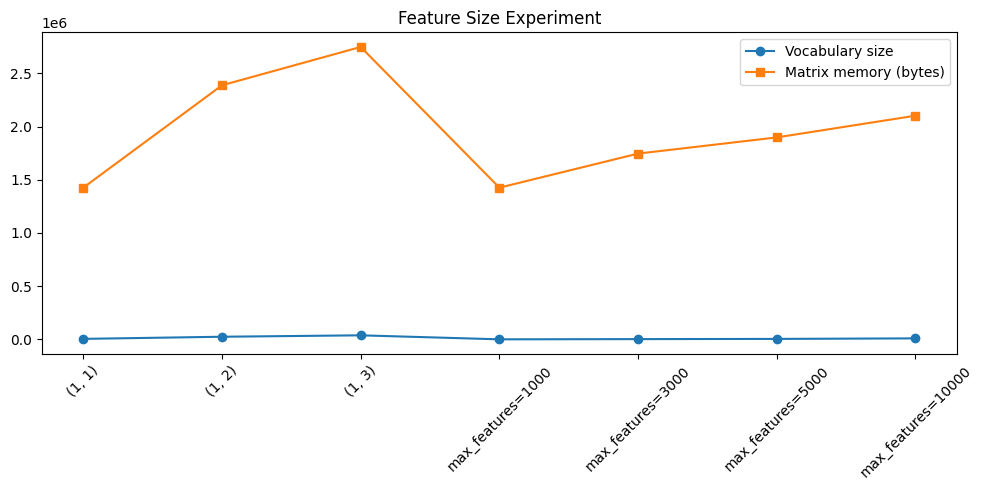

In [17]:
sizes = []
for n in [(1, 1), (1, 2), (1, 3)]:
    vec = TfidfVectorizer(ngram_range=n, min_df=2)
    mat = vec.fit_transform(X_train)
    sizes.append({'Setting': str(n), 'Vocabulary': len(vec.vocabulary_), 'Memory bytes': mat.data.nbytes})

for m in [1000, 3000, 5000, 10000]:
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=m)
    mat = vec.fit_transform(X_train)
    sizes.append({'Setting': 'max_features=' + str(m),
                  'Vocabulary': len(vec.vocabulary_), 'Memory bytes': mat.data.nbytes})

size_df = pd.DataFrame(sizes)
display(size_df)
plt.figure(figsize=(10, 5))
plt.plot(size_df['Setting'], size_df['Vocabulary'], marker='o', label='Vocabulary size')
plt.plot(size_df['Setting'], size_df['Memory bytes'], marker='s', label='Matrix memory (bytes)')
plt.xticks(rotation=45)
plt.title('Feature Size Experiment')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation -** A sensible setting keeps enough useful features while controlling memory and sparsity. The best setting should be selected using training data and validation, not by tuning on the test set.

## Task 5: Word Embeddings, Word2Vec — CBoW & Skip-gram


### 5.1 Word embeddings

BoW and TF-IDF represent each word as a separate column. Their vectors are usually sparse and do not directly represent word meaning. Word embeddings represent a word as a short, dense vector, such as 100 numbers. Words used in similar contexts can have similar vectors. This follows the idea: **“a word is known by the company it keeps.”**

**Interpretation -** Word2Vec learns word relationships from the surrounding words in the training text.

### 5.2 CBoW vs Skip-gram

| Point | CBoW | Skip-gram |
|---|---|---|
| Input | Surrounding context words | Centre word |
| Output | Centre word | Context words |
| Training speed | Usually faster | Usually slower |
| Rare words | Often weaker | Often better |
| Frequent words | Usually good | Usually good |
| Prefer when | Faster training is needed | Rare-word learning is important |

Sentence: **the flight was delayed again**, window = 2.

- CBoW: `[the, was] → flight`; `[flight, delayed] → was`; `[was, again] → delayed`
- Skip-gram: `flight → the, was`; `was → flight, delayed`; `delayed → was, again`

**Interpretation -** CBoW predicts a centre word from context. Skip-gram predicts context words from a centre word.

### 5.3 Train both Word2Vec models

In [18]:
from gensim.models import Word2Vec

train_tokens = X_train.apply(get_tokens).tolist()

start = time.time()
cbow = Word2Vec(sentences=train_tokens, vector_size=100, window=5,
                min_count=3, sg=0, epochs=20, seed=42, workers=1)
cbow_time = time.time() - start

start = time.time()
skip = Word2Vec(sentences=train_tokens, vector_size=100, window=5,
                min_count=3, sg=1, epochs=20, seed=42, workers=1)
skip_time = time.time() - start

print('CBoW vocabulary:', len(cbow.wv))
print('CBoW vector shape:', cbow.wv.vectors.shape)
print('CBoW training time:', round(cbow_time, 2), 'seconds')
print('Skip-gram vocabulary:', len(skip.wv))
print('Skip-gram vector shape:', skip.wv.vectors.shape)
print('Skip-gram training time:', round(skip_time, 2), 'seconds')

CBoW vocabulary: 3699
CBoW vector shape: (3699, 100)
CBoW training time: 3.73 seconds
Skip-gram vocabulary: 3699
Skip-gram vector shape: (3699, 100)
Skip-gram training time: 9.43 seconds


**Interpretation -** Both models learn 100-dimensional word vectors from training tweets only. Training time and vocabulary size show the basic difference between the two models.

### 5.4 Explore the vectors

In [19]:
queries = ['delayed', 'flight', 'thanks', 'rude', 'luggage', 'great']
similar_rows = []
for model_name, model in [('CBoW', cbow), ('Skip-gram', skip)]:
    for word in queries:
        if word in model.wv:
            similar = model.wv.most_similar(word, topn=5)
            similar_rows.append({'Model': model_name, 'Word': word,
                                 'Similar words': str(similar)})
display(pd.DataFrame(similar_rows))

pairs = [('delayed', 'late'), ('good', 'great'), ('flight', 'banana')]
for a, b in pairs:
    if a in skip.wv and b in skip.wv:
        print(a, '-', b, ':', round(skip.wv.similarity(a, b), 4))
    else:
        print(a, '-', b, ': word not in vocabulary')

,Model,Word,Similar words
0,CBoW,delayed,"[('four', 0.8114368915557861), ('missed', 0.80..."
1,CBoW,flight,"[('flt', 0.7233616709709167), ('flights', 0.71..."
2,CBoW,thanks,"[('thank', 0.8453028202056885), ('thx', 0.6808..."
3,CBoW,rude,"[('unhelpful', 0.8569471836090088), ('staff', ..."
4,CBoW,luggage,"[('bag', 0.8792849183082581), ('baggage', 0.84..."
5,CBoW,great,"[('awesome', 0.8718960285186768), ('amazing', ..."
6,Skip-gram,delayed,"[('manchester', 0.605073094367981), ('tire', 0..."
7,Skip-gram,flight,"[('discovered', 0.7147846817970276), ('woo', 0..."
8,Skip-gram,thanks,"[('thank', 0.6831314563751221), ('thx', 0.5665..."
9,Skip-gram,rude,"[('unhelpful', 0.7463258504867554), ('yelled',..."


delayed - late : 0.371
good - great : 0.3224
flight - banana : word not in vocabulary


**Interpretation -** Neighbour words and cosine similarities show which words have similar contexts. This dataset is relatively small, so its vectors can be noisier than vectors trained on very large text collections.

### 5.5 Visualise embeddings with PCA

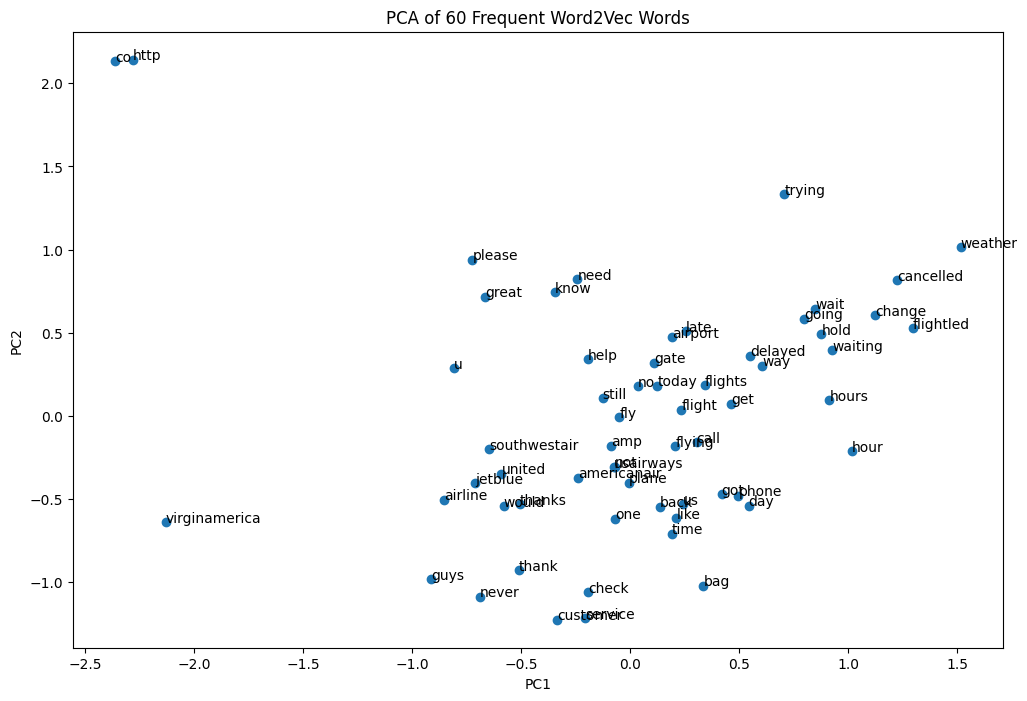

In [20]:
from sklearn.decomposition import PCA

top_words = [w for w, c in Counter([w for row in train_tokens for w in row]).most_common(60)
             if w in skip.wv]
if len(top_words) >= 2:
    word_vectors = np.array([skip.wv[w] for w in top_words])
    points = PCA(n_components=2).fit_transform(word_vectors)
    plt.figure(figsize=(12, 8))
    plt.scatter(points[:, 0], points[:, 1])
    for i, word in enumerate(top_words):
        plt.annotate(word, (points[i, 0], points[i, 1]))
    plt.title('PCA of 60 Frequent Word2Vec Words')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.show()
else:
    print('Not enough words are available for PCA.')

**Interpretation -** Words close together have more similar vector patterns. Possible groups may include complaint words, airline words and thank-you words.

### 5.6 From word vectors to document vectors

In [21]:
def doc_vector(tokens, model):
    vecs = [model.wv[w] for w in tokens if w in model.wv]
    if len(vecs) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vecs, axis=0)

X_train_w2v = np.array([doc_vector(get_tokens(x), skip) for x in X_train])
X_test_w2v = np.array([doc_vector(get_tokens(x), skip) for x in X_test])
print('Word2Vec train shape:', X_train_w2v.shape)
print('Word2Vec test shape:', X_test_w2v.shape)

Word2Vec train shape: (11683, 100)
Word2Vec test shape: (2921, 100)


**Interpretation -** Averaging word vectors creates one vector for each tweet. Averaging can lose word order, sentence structure and some negation information.

## Task 6: Text Classification Pipeline & Approach Comparison


### 6.1 Text classification and pipeline

Text classification assigns one label to a complete document. In this project, the labels are negative, neutral and positive. The pipeline is: raw tweet → cleaning → numeric features → classifier → predicted sentiment → evaluation. A scikit-learn Pipeline keeps feature extraction and classification together. It fits the vectoriser on training data and helps prevent data leakage. It also makes saving and using the model easier.

**Interpretation -** A single pipeline makes the training and prediction steps consistent and safer.

### 6.2 Build the baseline pipeline

Accuracy: 0.7908250599109894
Macro-F1: 0.7391578278584946
              precision    recall  f1-score   support

    negative       0.89      0.85      0.87      1832
     neutral       0.60      0.69      0.64       618
    positive       0.72      0.70      0.71       471

    accuracy                           0.79      2921
   macro avg       0.73      0.75      0.74      2921
weighted avg       0.80      0.79      0.79      2921



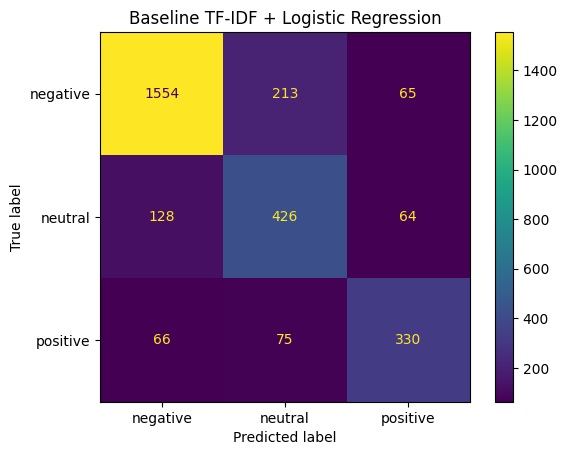

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

baseline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
])
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)
print('Accuracy:', accuracy_score(y_test, base_pred))
print('Macro-F1:', f1_score(y_test, base_pred, average='macro'))
print(classification_report(y_test, base_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, base_pred)
plt.title('Baseline TF-IDF + Logistic Regression')
plt.show()

**Interpretation -** `class_weight='balanced'` gives more weight to less frequent classes. This can help the model pay attention to neutral and positive tweets as well as negative tweets.

### 6.3 Compare feature approaches

In [23]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.base import clone

models = [
    ('BoW', 'Naive Bayes', Pipeline([('vec', CountVectorizer()), ('clf', MultinomialNB())])),
    ('BoW', 'Logistic Regression', Pipeline([('vec', CountVectorizer()), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))])),
    ('TF-IDF unigram', 'Logistic Regression', Pipeline([('vec', TfidfVectorizer(ngram_range=(1, 1), min_df=2)), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))])),
    ('TF-IDF unigram+bigram', 'Logistic Regression', Pipeline([('vec', TfidfVectorizer(ngram_range=(1, 2), min_df=2)), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))]))
]

results = []
fitted_models = {}
for feat, clf_name, model in models:
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    pred = model.predict(X_test)
    results.append({
        'Features': feat, 'Classifier': clf_name,
        'Accuracy': accuracy_score(y_test, pred),
        'Macro-F1': f1_score(y_test, pred, average='macro'),
        'Precision (negative)': precision_score(y_test, pred, labels=['negative'], average='macro', zero_division=0),
        'Recall (positive)': recall_score(y_test, pred, labels=['positive'], average='macro', zero_division=0),
        'Training time': round(train_time, 2)
    })
    fitted_models[feat] = model

# Word2Vec averaged vectors + Logistic Regression
w2v_clf = LogisticRegression(max_iter=1000, class_weight='balanced')
start = time.time()
w2v_clf.fit(X_train_w2v, y_train)
w2v_time = time.time() - start
w2v_pred = w2v_clf.predict(X_test_w2v)
results.append({
    'Features': 'Word2Vec average', 'Classifier': 'Logistic Regression',
    'Accuracy': accuracy_score(y_test, w2v_pred),
    'Macro-F1': f1_score(y_test, w2v_pred, average='macro'),
    'Precision (negative)': precision_score(y_test, w2v_pred, labels=['negative'], average='macro', zero_division=0),
    'Recall (positive)': recall_score(y_test, w2v_pred, labels=['positive'], average='macro', zero_division=0),
    'Training time': round(w2v_time, 2)
})
results_df = pd.DataFrame(results)
display(results_df.sort_values('Macro-F1', ascending=False))

,Features,Classifier,Accuracy,Macro-F1,Precision (negative),Recall (positive),Training time
3,TF-IDF unigram+bigram,Logistic Regression,0.790825,0.739158,0.889016,0.700637,1.61
1,BoW,Logistic Regression,0.775077,0.727615,0.900242,0.717622,1.15
2,TF-IDF unigram,Logistic Regression,0.771311,0.723509,0.901769,0.723992,0.75
4,Word2Vec average,Logistic Regression,0.737761,0.683995,0.882498,0.698514,0.45
0,BoW,Naive Bayes,0.763437,0.655100,0.772828,0.494692,0.29


**Interpretation -** The table compares five feature and classifier combinations on the same test set. The highest macro-F1 is the strongest balanced result among these tested combinations.

### 6.4 Compare all NLP approaches

,Approach,Macro-F1
5,TF-IDF unigram+bigram,0.739158
4,TF-IDF unigram,0.723509
6,Word2Vec average,0.683995
2,BoW,0.655100
1,VADER,0.507795
0,Heuristic,0.481740


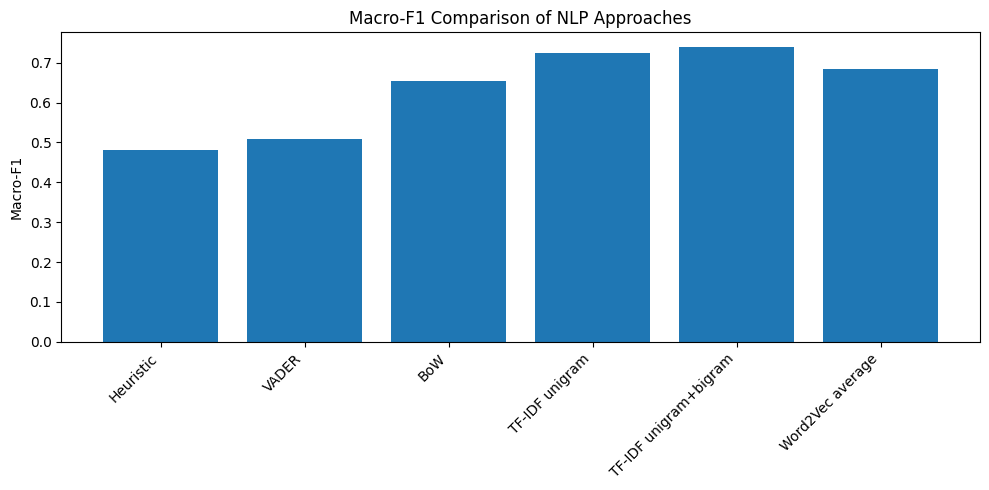

Best tested feature approach: TF-IDF unigram+bigram


In [24]:
all_results = [
    {'Approach': 'Heuristic', 'Macro-F1': f1_score(y_test, h_pred, average='macro')},
    {'Approach': 'VADER', 'Macro-F1': f1_score(y_test, v_pred, average='macro')}
]
for _, row in results_df.iterrows():
    all_results.append({'Approach': row['Features'], 'Macro-F1': row['Macro-F1']})

all_results_df = pd.DataFrame(all_results).drop_duplicates('Approach')
display(all_results_df.sort_values('Macro-F1', ascending=False))

plt.figure(figsize=(10, 5))
plt.bar(all_results_df['Approach'], all_results_df['Macro-F1'])
plt.title('Macro-F1 Comparison of NLP Approaches')
plt.ylabel('Macro-F1')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

best_name = results_df.sort_values('Macro-F1', ascending=False).iloc[0]['Features']
print('Best tested feature approach:', best_name)

**Interpretation -** The ranking is based on measured macro-F1. A suitable deployment choice should also consider speed, simplicity, privacy and how easy the model is to maintain.

### 6.5 Cross-validation of the best pipeline

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

best_pipeline = fitted_models[best_name]
if best_name == 'Word2Vec average':
    print('Word2Vec uses pre-built dense vectors, so the text pipeline cross-validation is not run here.')
else:
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_val_score(best_pipeline, X_train, y_train, cv=cv, scoring='f1_macro')
    print('CV scores:', cv_scores)
    print('CV mean:', round(cv_scores.mean(), 4))
    print('CV standard deviation:', round(cv_scores.std(), 4))
    print('Test macro-F1:', round(f1_score(y_test, best_pipeline.predict(X_test), average='macro'), 4))

CV scores: [0.74253965 0.74957492 0.73399482 0.76149124 0.73662618]
CV mean: 0.7448
CV standard deviation: 0.0099
Test macro-F1: 0.7392


**Interpretation -** Cross-validation measures performance across five training folds. A large difference between cross-validation and test macro-F1 may suggest overfitting or a difference in the data splits.

### 6.6 Error analysis

In [26]:
error_df = pd.DataFrame({
    'text': X_test,
    'true': y_test,
    'predicted': baseline.predict(X_test),
    'confidence': baseline.predict_proba(X_test).max(axis=1)
})
errors = error_df[error_df['true'] != error_df['predicted']].head(8)
display(errors)

print('Error counts by true and predicted label:')
display(pd.crosstab(error_df.loc[error_df['true'] != error_df['predicted'], 'true'],
                    error_df.loc[error_df['true'] != error_df['predicted'], 'predicted']))

,text,true,predicted,confidence
10909,usairways call gate d in clt and get me on th...,neutral,negative,0.668268
3687,united have reported it still in istanbul at...,positive,negative,0.543412
453,virginamerica that s classy,positive,neutral,0.558671
730,united thanks for the lack of help and the can...,negative,positive,0.519231
6258,southwestair how does your pre boarding proces...,negative,neutral,0.487132
4189,united priceless united stranded my daughter ...,negative,neutral,0.404476
11817,usairways i booked a flight yesterday but didn...,negative,neutral,0.581388
2654,united will the airline refuse my canadian pas...,neutral,negative,0.539731


Error counts by true and predicted label:


predicted,negative,neutral,positive
true,,,
negative,0,213,65
neutral,128,0,64
positive,66,75,0


**Interpretation -** Misclassified tweets can include sarcasm, short messages, mixed feelings or neutral tweets that look negative. Two possible improvements within this practical are testing trigrams and adjusting `min_df` or `max_features` using training validation.

### 6.7 Save the final pipeline

In [27]:
import joblib
import sklearn

# Save the TF-IDF baseline pipeline for a simple end-to-end text model.
joblib.dump(baseline, 'sentiment_model.joblib')
loaded_model = joblib.load('sentiment_model.joblib')

new_texts = [
    'thank you the crew was great',
    'my flight was delayed and service was bad',
    'the flight was on time'
]
new_clean = [clean_text(x) for x in new_texts]
print('Predictions:', loaded_model.predict(new_clean))
print('scikit-learn version:', sklearn.__version__)

Predictions: ['positive' 'negative' 'negative']
scikit-learn version: 1.8.0


**Interpretation -** The saved pipeline contains the vectoriser and classifier. It is reloaded and tested on three new sentences. Use the printed scikit-learn version in the deployment requirements file.

## Task 7: POS Tagging


### 7.1 What is POS tagging?

Part-of-speech (POS) tagging assigns a grammar label to each word. Common Penn Treebank tags include:

| Word type | Tag | Example |
|---|---|---|
| Noun | NN | flight |
| Verb | VB | travel |
| Adjective | JJ | delayed |
| Adverb | RB | quickly |
| Pronoun | PRP | we |
| Preposition | IN | in |

POS tagging is useful for information extraction, grammar checking, better text features and understanding words with different meanings.

**Interpretation -** POS tagging tells us how each word is used in a sentence.

### 7.2 How POS tagging works

1. A rule-based tagger uses dictionaries and manually written rules.
2. A statistical tagger learns tag patterns from a tagged text collection. Examples include Hidden Markov Models and averaged perceptron taggers.
3. Context helps solve ambiguity. For example, “I park the car” uses `park` as a verb, while “the park is green” uses `park` as a noun. “I read a book” uses `book` as a noun, while “I book a ticket” uses `book` as a verb.

NLTK `pos_tag` uses a trained averaged-perceptron tagger. It was trained on news-style text, so informal tweets may be difficult for it.

**Interpretation -** A tagger uses word patterns and nearby words to select a grammar label.

### 7.3 Tag sentences

In [28]:
nltk.download('averaged_perceptron_tagger', quiet=True)
try:
    nltk.download('averaged_perceptron_tagger_eng', quiet=True)
except:
    pass

from nltk import pos_tag

sample_tweets = df['clean_text'].head(5).tolist()
ambiguity = ['I park the car near the office', 'The park is full of people',
             'I book a flight today', 'This book is interesting']
tag_rows = []
for sentence in sample_tweets + ambiguity[:2]:
    words = word_tokenize(sentence)
    tags = pos_tag(words)
    tag_rows.append({'Sentence': sentence, 'Word and POS tags': str(tags)})
display(pd.DataFrame(tag_rows))

print('Ambiguity examples:')
for sentence in ambiguity:
    print(sentence, '->', pos_tag(word_tokenize(sentence)))

,Sentence,Word and POS tags
0,virginamerica what dhepburn said,"[('virginamerica', 'NN'), ('what', 'WP'), ('dh..."
1,virginamerica plus you ve added commercials to...,"[('virginamerica', 'NN'), ('plus', 'CC'), ('yo..."
2,virginamerica i didn t today must mean i ne...,"[('virginamerica', 'NN'), ('i', 'NN'), ('didn'..."
3,virginamerica it s really aggressive to blast ...,"[('virginamerica', 'NN'), ('it', 'PRP'), ('s',..."
4,virginamerica and it s a really big bad thing ...,"[('virginamerica', 'NN'), ('and', 'CC'), ('it'..."
5,I park the car near the office,"[('I', 'PRP'), ('park', 'VBP'), ('the', 'DT'),..."
6,The park is full of people,"[('The', 'DT'), ('park', 'NN'), ('is', 'VBZ'),..."


Ambiguity examples:
I park the car near the office -> [('I', 'PRP'), ('park', 'VBP'), ('the', 'DT'), ('car', 'NN'), ('near', 'IN'), ('the', 'DT'), ('office', 'NN')]
The park is full of people -> [('The', 'DT'), ('park', 'NN'), ('is', 'VBZ'), ('full', 'JJ'), ('of', 'IN'), ('people', 'NNS')]
I book a flight today -> [('I', 'PRP'), ('book', 'NN'), ('a', 'DT'), ('flight', 'NN'), ('today', 'NN')]
This book is interesting -> [('This', 'DT'), ('book', 'NN'), ('is', 'VBZ'), ('interesting', 'JJ')]


**Interpretation -** POS tags depend on context. Tweets are harder than news text because they often contain informal language, spelling mistakes and missing punctuation. Some tags may therefore look incorrect.

### 7.4 POS distribution by sentiment

,Adjectives (JJ),Adverbs (RB),Verbs (VB),Nouns (NN)
Sentiment,,,,
negative,0.094150,0.057367,0.213922,0.305175
neutral,0.094861,0.039436,0.201902,0.358376
positive,0.116616,0.055987,0.180191,0.345759


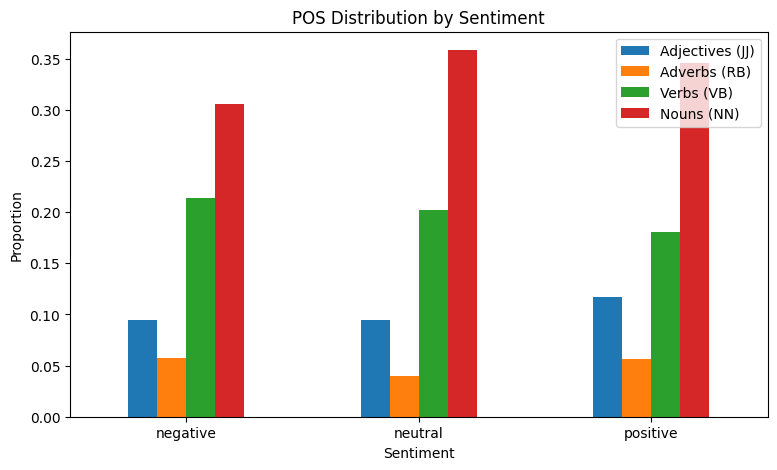

Top 10 adjectives - negative [('united', 518), ('i', 171), ('t', 112), ('usairways', 111), ('late', 82), ('last', 56), ('more', 51), ('worst', 48), ('due', 40), ('flightled', 40)]
Top 10 adjectives - positive [('united', 374), ('great', 180), ('i', 115), ('jetblue', 93), ('good', 88), ('best', 88), ('awesome', 73), ('usairways', 62), ('t', 50), ('much', 48)]


In [29]:
sample_df = df.loc[X_train.index].groupby('airline_sentiment', group_keys=False).head(2000)
pos_counts = []
adjective_words = {}

for label in ['negative', 'neutral', 'positive']:
    words_all = []
    for sentence in sample_df.loc[sample_df['airline_sentiment'] == label, 'clean_text']:
        words = word_tokenize(sentence)
        tags = pos_tag(words)
        words_all.extend(tags)
    total = max(len(words_all), 1)
    pos_counts.append({
        'Sentiment': label,
        'Adjectives (JJ)': sum(1 for w, t in words_all if t.startswith('JJ')) / total,
        'Adverbs (RB)': sum(1 for w, t in words_all if t.startswith('RB')) / total,
        'Verbs (VB)': sum(1 for w, t in words_all if t.startswith('VB')) / total,
        'Nouns (NN)': sum(1 for w, t in words_all if t.startswith('NN')) / total
    })
    adjective_words[label] = Counter(w.lower() for w, t in words_all if t.startswith('JJ'))

pos_df = pd.DataFrame(pos_counts).set_index('Sentiment')
display(pos_df)
pos_df.plot(kind='bar', figsize=(9, 5))
plt.title('POS Distribution by Sentiment')
plt.ylabel('Proportion')
plt.xticks(rotation=0)
plt.show()

for label in ['negative', 'positive']:
    print('Top 10 adjectives -', label, adjective_words[label].most_common(10))

**Interpretation -** The chart compares the proportion of nouns, verbs, adjectives and adverbs in each sentiment group. The adjective lists show descriptive words used in negative and positive tweets.

### 7.5 POS-filtered features

In [30]:
def pos_filter_text(text):
    words = word_tokenize(text)
    tags = pos_tag(words)
    keep = []
    for word, tag in tags:
        if tag.startswith(('JJ', 'RB', 'VB')) or word in {'no', 'not', 'nor', 'never'}:
            keep.append(word)
    return ' '.join(keep)

X_train_pos = X_train.apply(pos_filter_text)
X_test_pos = X_test.apply(pos_filter_text)

pos_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
])
pos_pipeline.fit(X_train_pos, y_train)
pos_pred = pos_pipeline.predict(X_test_pos)

full_f1 = f1_score(y_test, baseline.predict(X_test), average='macro')
pos_f1 = f1_score(y_test, pos_pred, average='macro')
display(pd.DataFrame([
    {'Text features': 'Full text', 'Macro-F1': full_f1},
    {'Text features': 'POS filtered', 'Macro-F1': pos_f1}
]))
print('Full text macro-F1:', round(full_f1, 4))
print('POS filtered macro-F1:', round(pos_f1, 4))

,Text features,Macro-F1
0,Full text,0.739158
1,POS filtered,0.648734


Full text macro-F1: 0.7392
POS filtered macro-F1: 0.6487


**Interpretation -** Compare both macro-F1 values. POS filtering may help if useful descriptive words remain, or hurt if important nouns and other context words are removed. Report the measured result honestly.